# Presentation figures (all 12 slide figures)

Recreates every figure in `presentation_figs/light/` (16:9, 150 dpi, PNG + PDF), one cell per figure, so you can
edit titles, wording, colours and layout.

**Where this notebook lives:** `presentation/`. The image figures (4, 5, 6) read images from
`report_figures/...` and `dataset/images/` (extract the dataset zip from the GitHub Release), using the relative paths in the settings cell. If you move the notebook, update `REPORT` and `DATASET`.

**Data:** all numbers are copied into the data cell from the analysis of the pooled out-of-fold test predictions
(120 runs; seeds averaged). Detection is scored with box IoU and segmentation with mask IoU. Figure 10 (error breakdown)
uses confidence ≥ 0.25 and box IoU ≥ 0.5 for all models. CIs are 95% paired block-bootstrap intervals (2,000 resamples of 49 blocks).

Set `THEME = 'dark'` to produce the dark versions instead.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

THEME = 'light'                 # 'light' or 'dark'
REPORT = '../report_figures'    # repo folder with the figure images
DATASET = '../dataset/images'   # extract the dataset zip (GitHub Release) into dataset/
OUT = THEME                     # figures are written to presentation_figs/<THEME>/
SAVE = True
DPI = 150
FS = (13.33, 7.5)               # 16:9 slide
os.makedirs(OUT, exist_ok=True)

## Data

In [2]:
# --- annotated instances per species (corrected CVAT labels, frames 1000-2461), sorted
COUNTS = {
    'Yellow Tang': 1119, 'Brown Surgeonfish': 875, 'Orangeband Surgeonfish': 568, 'Blackfin Chromis': 310,
    'Goldring Surgeonfish': 252, 'Moorish Idol': 143, 'Raccoon Butterflyfish': 101, 'Ornate Butterflyfish': 99,
    'Forcepsfish': 93, 'Orangespine Unicornfish': 77, 'Acanthuridae': 56, 'Lowfin Chub': 41, 'Convict Tang': 33,
    'Black Triggerfish': 30, 'Redlip Parrotfish - Male': 30, 'Redlip Parrotfish - Female': 27, 'Lei Triggerfish': 25,
    'Fourspot Butterflyfish': 22, 'Doublebar Goatfish': 21, 'Multiband Butterflyfish': 21,
    'Bullethead Parrotfish - Female': 18, 'Hawaiian Whitespotted Toby': 15, 'Bullethead Parrotfish': 14,
    'Whitebar Surgeonfish': 13, 'Whitecheek Surgeonfish': 11, 'Whitespotted Surgeonfish': 11, 'Chinese Trumpetfish': 9,
    'Blue Goatfish': 9, 'Bluefin Trevally': 8, 'Saddle Wrasse - Male': 8, 'Ringtail Surgeonfish': 8,
    'Lined Butterflyfish': 7, 'Indo-Pacific Sergeant': 6, 'Chevron Tang': 5, 'Highfin Chub': 4,
    'Longnose Butterflyfish': 4, 'Manybar Goatfish': 2, 'Hawaiian Cleaner Wrasse': 1, 'Pyramid Butterflyfish': 1,
    'Palenose Parrotfish - Male': 1}
FOCUS_SP = ['Forcepsfish', 'Orangespine Unicornfish', 'Convict Tang']

# --- cross-validation: block b covers frames 1000+30b ... (last block shorter); fold of each block 0..48
FRAMES = np.arange(1000, 2462)
BLOCK_FOLD = [3, 1, 2, 2, 4, 3, 0, 1, 3, 3, 1, 1, 2, 3, 3, 2, 0, 1, 0, 0, 4, 0, 1, 3, 0, 4, 2, 1, 1, 3, 1, 0, 4, 3,
              3, 4, 0, 4, 2, 4, 4, 2, 1, 0, 2, 2, 0, 2, 4]
BUFFER = 15

# --- per model (baseline models unless stated)
SETUPS = ['detect_s', 'detect_m', 'detect_l', 'segment_s', 'segment_m', 'segment_l']
LAB = {'detect_s': 'Detection S', 'detect_m': 'Detection M', 'detect_l': 'Detection L',
       'segment_s': 'Segmentation S', 'segment_m': 'Segmentation M', 'segment_l': 'Segmentation L'}
ANYFISH = {'detect_s': 0.6704, 'detect_m': 0.6935, 'detect_l': 0.6806, 'segment_s': 0.6761, 'segment_m': 0.6890, 'segment_l': 0.6797}
MACRO = {'detect_s': 0.2624, 'detect_m': 0.3017, 'detect_l': 0.3057, 'segment_s': 0.2548, 'segment_m': 0.2803, 'segment_l': 0.3024}
FOCUS_BASE = {'detect_s': 0.2672, 'detect_m': 0.3355, 'detect_l': 0.3727, 'segment_s': 0.2393, 'segment_m': 0.3084, 'segment_l': 0.3608}
FOCUS_AUG = {'detect_s': 0.3572, 'detect_m': 0.4240, 'detect_l': 0.4404, 'segment_s': 0.3553, 'segment_m': 0.4576, 'segment_l': 0.4444}
HOLM = {'detect_s': 'p = 0.027', 'detect_m': 'p = 0.004', 'detect_l': 'p = 0.027',
        'segment_s': 'p < 0.006', 'segment_m': 'p < 0.006', 'segment_l': 'p = 0.027'}
# change (augmented - baseline) [estimate, CI low, CI high]
D_NONFOCUS = {'detect_s': [-0.005, -0.029, 0.031], 'detect_m': [-0.001, -0.016, 0.021], 'detect_l': [0.016, -0.007, 0.036],
              'segment_s': [0.006, -0.010, 0.023], 'segment_m': [0.026, 0.008, 0.051], 'segment_l': [0.020, -0.001, 0.049]}
D_ANYFISH = {'detect_s': [-0.003, -0.016, 0.012], 'detect_m': [-0.007, -0.019, 0.005], 'detect_l': [-0.008, -0.019, 0.001],
             'segment_s': [-0.009, -0.022, 0.004], 'segment_m': [0.009, -0.006, 0.027], 'segment_l': [0.004, -0.006, 0.017]}
GFLOPS = {'detect_s': 95, 'detect_m': 305, 'detect_l': 380, 'segment_s': 153, 'segment_m': 533, 'segment_l': 609}

# --- per focus species: AP50 averaged over the 6 models, and runs improved out of 12 model-seed runs
SPECIES_AVG = {'Convict Tang': (0.414, 0.580, 12), 'Forcepsfish': (0.358, 0.460, 11),
               'Orangespine Unicornfish': (0.170, 0.199, 9)}

# --- fate of each annotated focus-species fish: [correct, wrong species, poorly localised, missed]
FATE = {'Forcepsfish':             {'Baseline': [0.2679, 0.2473, 0.0824, 0.4023], 'Augmented': [0.4032, 0.1720, 0.0565, 0.3683]},
        'Orangespine Unicornfish': {'Baseline': [0.1548, 0.1537, 0.0271, 0.6645], 'Augmented': [0.1959, 0.1418, 0.0184, 0.6439]},
        'Convict Tang':            {'Baseline': [0.3561, 0.1162, 0.0025, 0.5253], 'Augmented': [0.5884, 0.0758, 0.0025, 0.3333]}}

## Style

In [3]:
THEMES = {
    'light': dict(bg='#ffffff', ink='#0b0b0b', ink2='#52514e', grid='#e1e0d9', axis='#898781', base='#a3a29b',
                  blue='#2a78d6', orange='#eb6834', violet='#6250d6', card='#f4f3ef'),
    'dark':  dict(bg='#0f1b2d', ink='#f0efec', ink2='#c3c2b7', grid='#26354b', axis='#6d7a8e', base='#7f8a9b',
                  blue='#4a90e8', orange='#e2683a', violet='#9085e9', card='#18283f'),
}
T = THEMES[THEME]
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 16, 'text.color': T['ink'],
                     'axes.labelcolor': T['ink2'], 'axes.edgecolor': T['axis'], 'xtick.color': T['ink2'],
                     'ytick.color': T['ink2'], 'axes.facecolor': T['bg'], 'figure.facecolor': T['bg'],
                     'savefig.facecolor': T['bg'], 'axes.titlesize': 20, 'axes.titleweight': 'bold',
                     'axes.titlecolor': T['ink'], 'axes.titlelocation': 'left', 'axes.titlepad': 14,
                     'legend.frameon': False, 'legend.fontsize': 15})

def clean(ax, grid='y'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    if grid: ax.grid(axis=grid, color=T['grid'], lw=1); ax.set_axisbelow(True)
    ax.tick_params(length=0)

def save(fig, name):
    if SAVE:
        for ext in ('png', 'pdf'): fig.savefig(os.path.join(OUT, f'{name}.{ext}'), dpi=DPI)
    plt.show()

## 01 Class imbalance

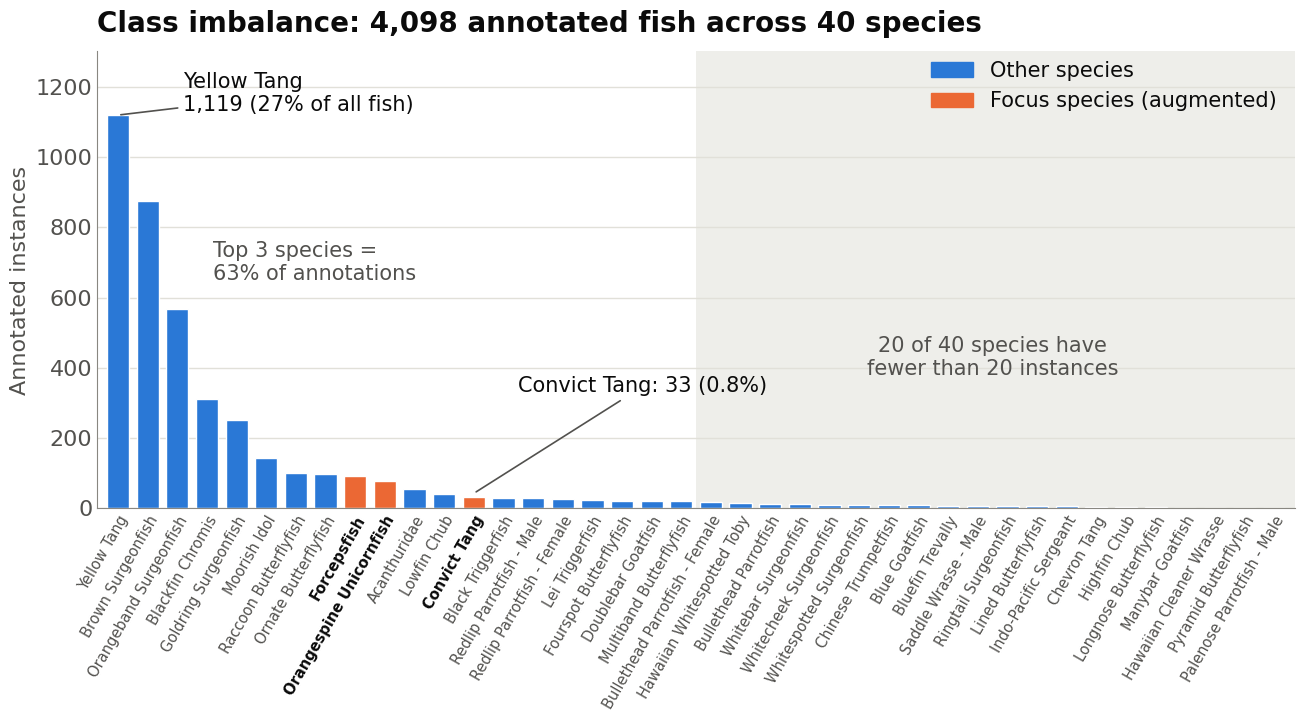

In [ ]:
names = list(COUNTS); vals = np.array([COUNTS[n] for n in names]); tot = vals.sum(); x = np.arange(len(names))
fig, ax = plt.subplots(figsize=FS)
ax.bar(x, vals, color=[T['orange'] if s in FOCUS_SP else T['blue'] for s in names], width=0.75, edgecolor=T['bg'], lw=1)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=60, ha='right', rotation_mode='anchor', fontsize=10.5)
for t in ax.get_xticklabels():
    if t.get_text() in FOCUS_SP: t.set_color(T['ink']); t.set_fontweight('bold')
ax.set_xlim(-0.7, len(names) - 0.3); ax.set_ylim(0, 1300); ax.set_ylabel('Annotated instances'); clean(ax)
yt = COUNTS['Yellow Tang']
ax.annotate(f'Yellow Tang\n{yt:,} ({yt / tot:.0%} of all fish)', (0, yt), (2.2, 1180), fontsize=15, va='center')
i = names.index('Convict Tang'); ct = COUNTS['Convict Tang']
ax.annotate(f'Convict Tang: {ct} ({ct / tot:.1%})', (i, ct + 10), (i + 1.5, 330), fontsize=15)
k = int((vals < 20).sum()); first = len(names) - k
ax.axvspan(first - 0.5, len(names) - 0.3, color=T['grid'], alpha=0.55, lw=0, zorder=0)
ax.text((first + len(names)) / 2 - 0.5, 380, f'{k} of {len(names)} species have\nfewer than 20 instances',
        ha='center', fontsize=15, color=T['ink2'])
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=T['blue']), Rectangle((0, 0), 1, 1, color=T['orange'])],
          labels=['Other species', 'Focus species (augmented)'], loc='upper right', bbox_to_anchor=(1, 1.02))
ax.set_title(f'Class imbalance: {tot:,} annotated fish across {len(names)} species')
fig.tight_layout(); save(fig, '01_class_imbalance')

## 02 Experimental design

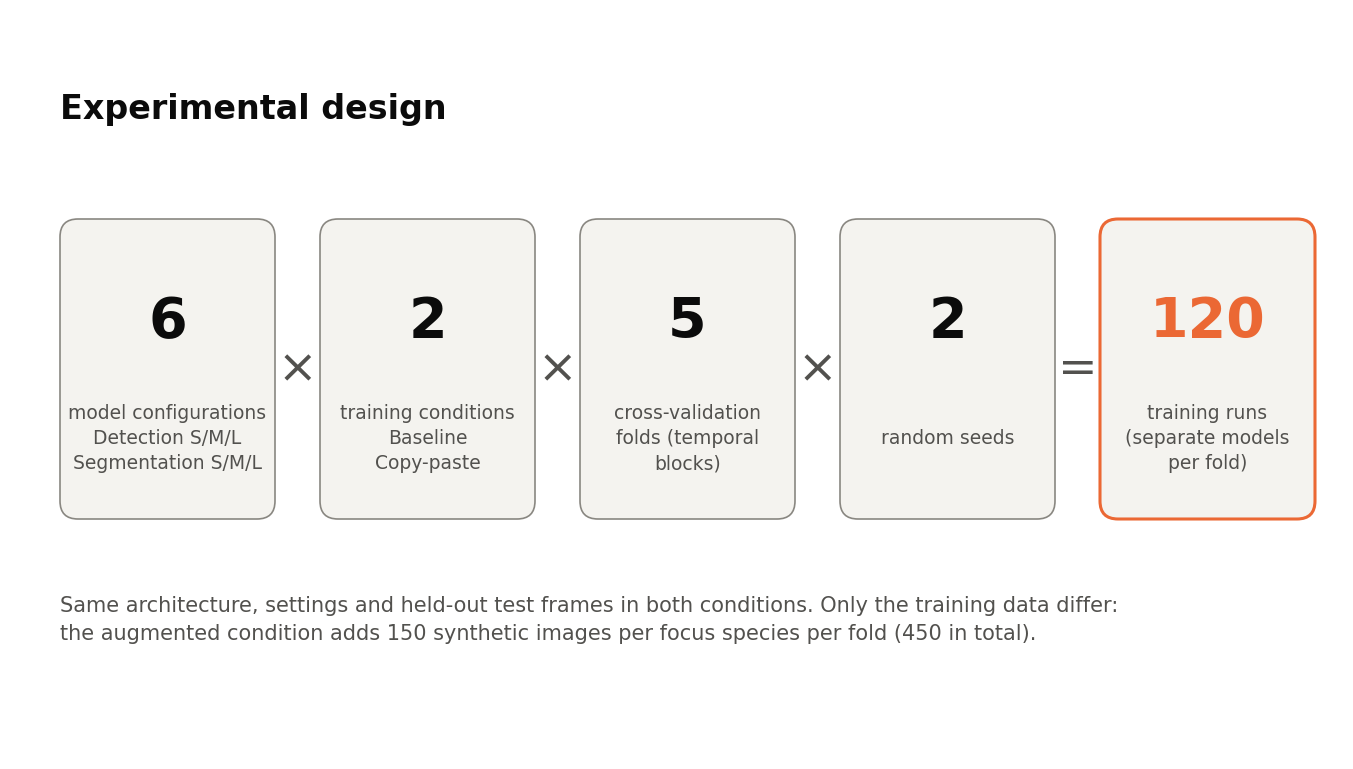

In [5]:
def card(ax, x, y, w, h, big, small, col=None):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0,rounding_size=0.18', fc=T['card'],
                                ec=col or T['axis'], lw=2.2 if col else 1.2))
    ax.text(x + w / 2, y + h * 0.66, big, ha='center', va='center', fontsize=40, fontweight='bold', color=col or T['ink'])
    ax.text(x + w / 2, y + h * 0.27, small, ha='center', va='center', fontsize=13.5, color=T['ink2'], linespacing=1.4)

fig = plt.figure(figsize=FS); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 13.33); ax.set_ylim(0, 7.5); ax.axis('off')
items = [('6', 'model configurations\nDetection S/M/L\nSegmentation S/M/L'),
         ('2', 'training conditions\nBaseline\nCopy-paste'),
         ('5', 'cross-validation\nfolds (temporal\nblocks)'),
         ('2', 'random seeds')]
w, h, y = 2.15, 3.0, 2.4; x = 0.5
for i, (b, s) in enumerate(items):
    card(ax, x, y, w, h, b, s)
    ax.text(x + w + 0.225, y + h / 2, '×' if i < 3 else '=', ha='center', va='center', fontsize=34, color=T['ink2'])
    x += w + 0.45
card(ax, x, y, w, h, '120', 'training runs\n(separate models\nper fold)', col=T['orange'])
ax.text(0.5, 6.5, 'Experimental design', fontsize=24, fontweight='bold', color=T['ink'], va='center')
ax.text(0.5, 1.4, 'Same architecture, settings and held-out test frames in both conditions. Only the training data differ:\n'
        'the augmented condition adds 150 synthetic images per focus species per fold (450 in total).',
        fontsize=15, color=T['ink2'], va='center', linespacing=1.5)
save(fig, '02_study_design')

## 03 Cross-validation folds

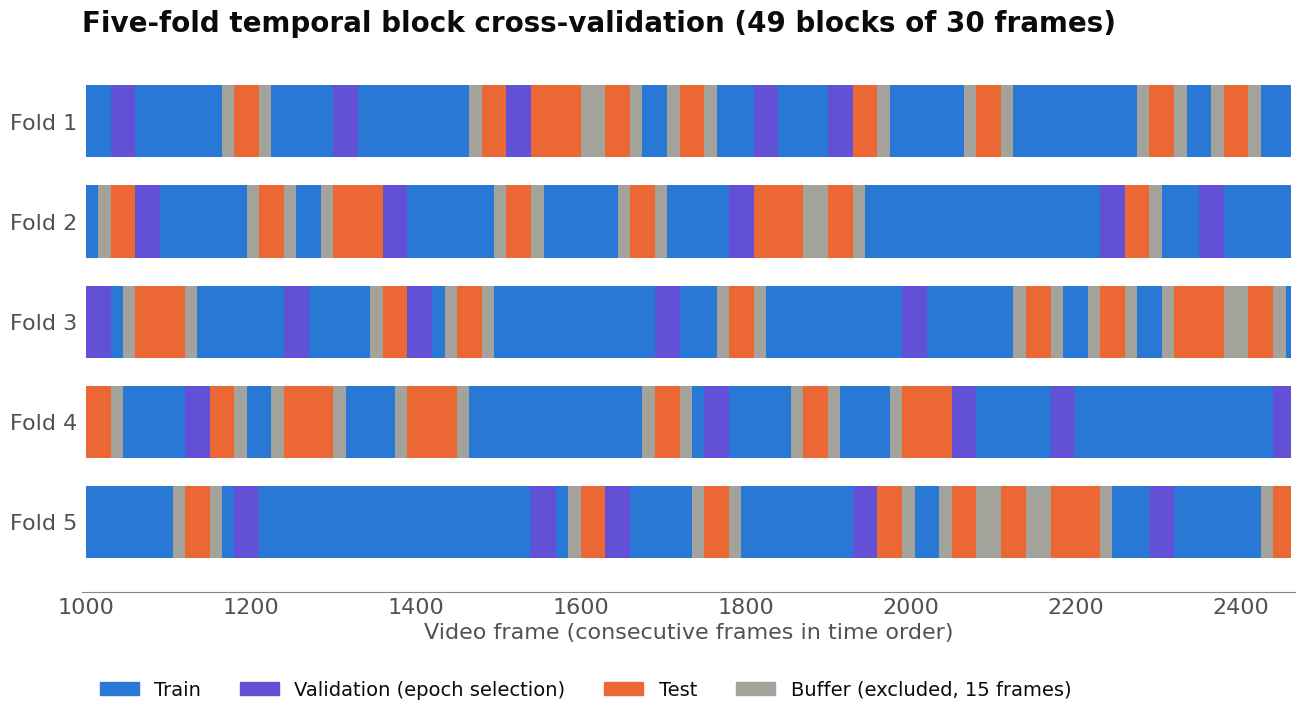

In [6]:
block = (FRAMES - 1000) // 30; fold = np.array([BLOCK_FOLD[b] for b in block])
cols = {'test': T['orange'], 'val': T['violet'], 'train': T['blue'], 'buffer': T['base']}
fig, ax = plt.subplots(figsize=FS)
for k in range(5):
    nxt = sorted(b for b in range(len(BLOCK_FOLD)) if BLOCK_FOLD[b] == (k + 1) % 5); vb = set(nxt[::2])  # val = every other block of fold k+1
    test = FRAMES[fold == k]
    role = []
    for f, b, fo in zip(FRAMES, block, fold):
        if fo == k: role.append('test')
        elif b in vb: role.append('val')
        elif np.min(np.abs(test - f)) <= BUFFER: role.append('buffer')
        else: role.append('train')
    yy = 4 - k; start = 0
    for i in range(1, len(FRAMES) + 1):
        if i == len(FRAMES) or role[i] != role[start]:
            ax.add_patch(Rectangle((FRAMES[start] - 0.5, yy - 0.36), FRAMES[i - 1] - FRAMES[start] + 1, 0.72,
                                   color=cols[role[start]], lw=0))
            start = i
ax.set_xlim(FRAMES.min() - 5, FRAMES.max() + 5); ax.set_ylim(-0.7, 4.7)
ax.set_yticks(range(5)); ax.set_yticklabels([f'Fold {k + 1}' for k in range(4, -1, -1)], fontsize=16)
ax.set_xlabel('Video frame (consecutive frames in time order)'); clean(ax, grid=None); ax.spines['left'].set_visible(False)
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=cols[c]) for c in ('train', 'val', 'test', 'buffer')],
          labels=['Train', 'Validation (epoch selection)', 'Test', f'Buffer (excluded, {BUFFER} frames)'],
          ncol=4, loc='upper left', bbox_to_anchor=(0, -0.13), fontsize=14)
ax.set_title('Five-fold temporal block cross-validation (49 blocks of 30 frames)')
fig.tight_layout(); save(fig, '03_cv_folds')

## 04 Copy-paste pipeline
Close-up crops: donor frame 1668, receiver frame 1950 (same paste as the report figure).

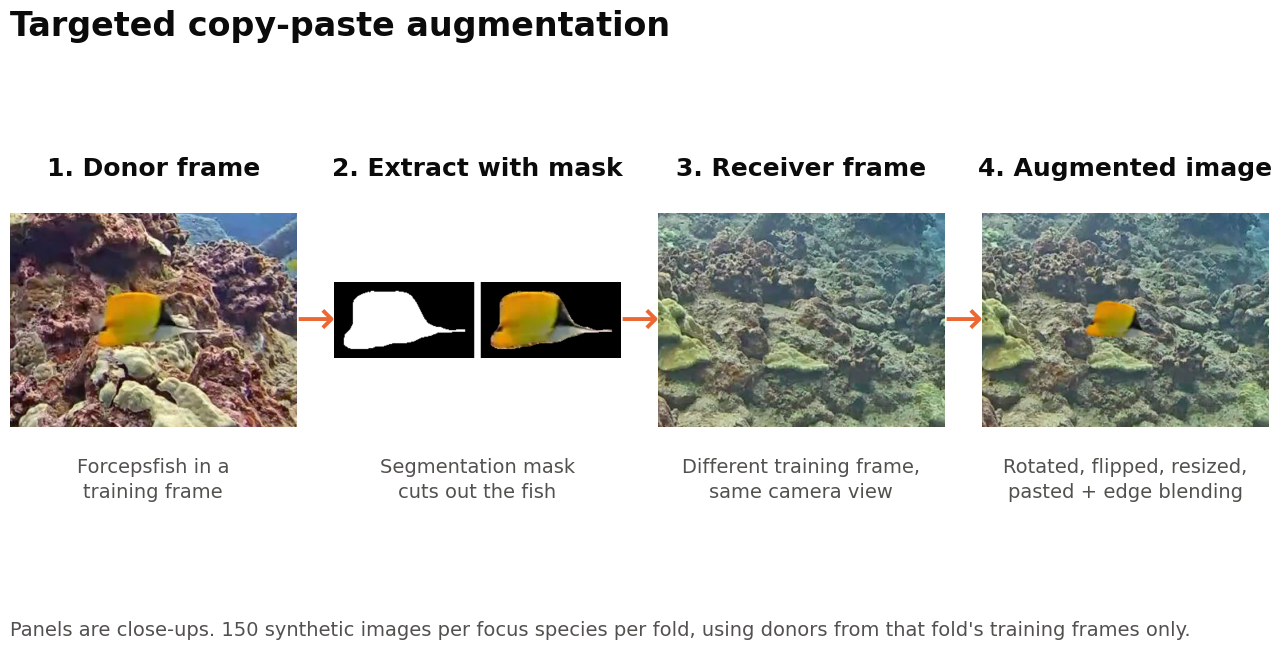

In [7]:
don = plt.imread(f'{DATASET}/frame_1668.jpg'); rec = plt.imread(f'{DATASET}/frame_1950.jpg')
aug = plt.imread(f'{REPORT}/blend_compare/b_poisson_edge_full.png')
b = plt.imread(f'{REPORT}/cp_steps/b_mask.png')
a = don[258:528, 881:1241]; c = rec[319:589, 370:730]; d = aug[319:589, 370:730]   # [rows, cols] crop windows
fig = plt.figure(figsize=FS)
panels = [(a, '1. Donor frame', 'Forcepsfish in a\ntraining frame'),
          (b, '2. Extract with mask', 'Segmentation mask\ncuts out the fish'),
          (c, '3. Receiver frame', 'Different training frame,\nsame camera view'),
          (d, '4. Augmented image', 'Rotated, flipped, resized,\npasted + edge blending')]
W = 0.215; gap = (1 - 4 * W) / 5; Hh = W * 13.33 / 7.5 * 0.75
for i, (img, t, s_) in enumerate(panels):
    x = gap + i * (W + gap)
    ax = fig.add_axes([x, 0.52 - Hh / 2, W, Hh]); ax.imshow(img); ax.axis('off')
    fig.text(x + W / 2, 0.52 + Hh / 2 + 0.05, t, ha='center', fontsize=18, fontweight='bold', color=T['ink'])
    fig.text(x + W / 2, 0.52 - Hh / 2 - 0.04, s_, ha='center', va='top', fontsize=14, color=T['ink2'], linespacing=1.4)
    if i < 3: fig.text(x + W + gap / 2, 0.52, '→', ha='center', va='center', fontsize=34, color=T['orange'])
fig.text(gap, 0.9, 'Targeted copy-paste augmentation', fontsize=24, fontweight='bold', color=T['ink'])
fig.text(gap, 0.1, "Panels are close-ups. 150 synthetic images per focus species per fold, using donors from "
         "that fold's training frames only.", fontsize=14, color=T['ink2'])
save(fig, '04_copy_paste_pipeline')

## 05 Blending

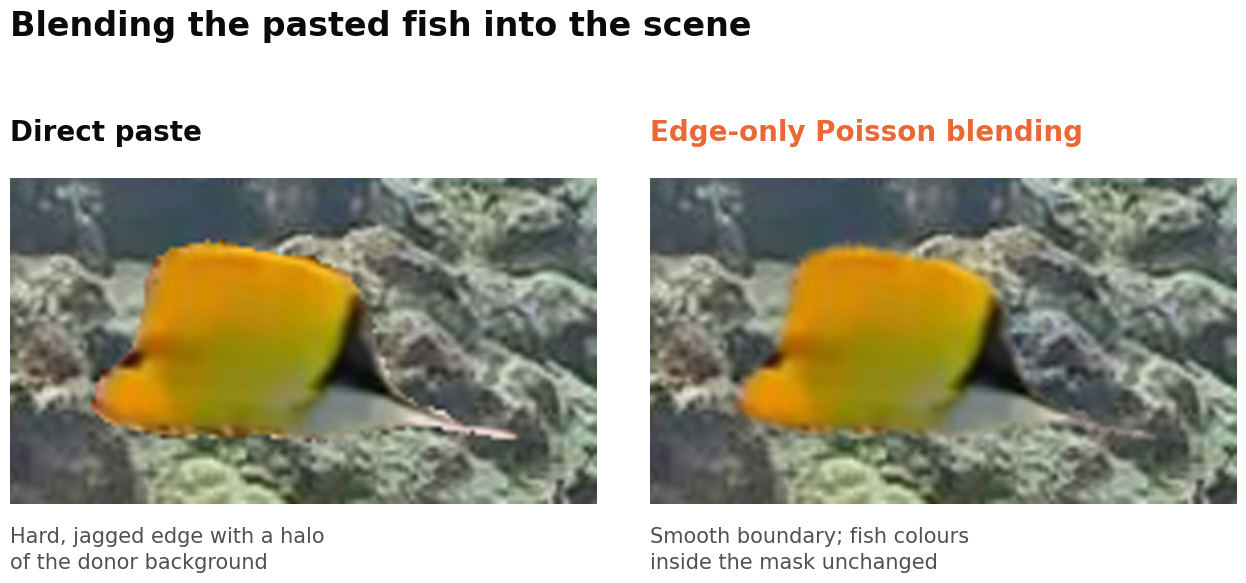

In [8]:
a = plt.imread(f'{REPORT}/blend_compare/a_naive_paste.png'); b = plt.imread(f'{REPORT}/blend_compare/b_poisson_edge.png')
fig = plt.figure(figsize=FS)
for i, (img, t, s) in enumerate([(a, 'Direct paste', 'Hard, jagged edge with a halo\nof the donor background'),
                                 (b, 'Edge-only Poisson blending', 'Smooth boundary; fish colours\ninside the mask unchanged')]):
    x = 0.04 + i * 0.48; hh = 0.44 * 13.33 / 7.5 * img.shape[0] / img.shape[1]
    ax = fig.add_axes([x, 0.74 - hh, 0.44, hh]); ax.imshow(img); ax.axis('off')
    fig.text(x, 0.79, t, fontsize=20, fontweight='bold', color=T['orange'] if i else T['ink'])
    fig.text(x, 0.74 - hh - 0.03, s, va='top', fontsize=15, color=T['ink2'], linespacing=1.4)
fig.text(0.04, 0.93, 'Blending the pasted fish into the scene', fontsize=24, fontweight='bold', color=T['ink'])
save(fig, '05_blending')

## 06 Detection vs segmentation (frame 2189, cropped)

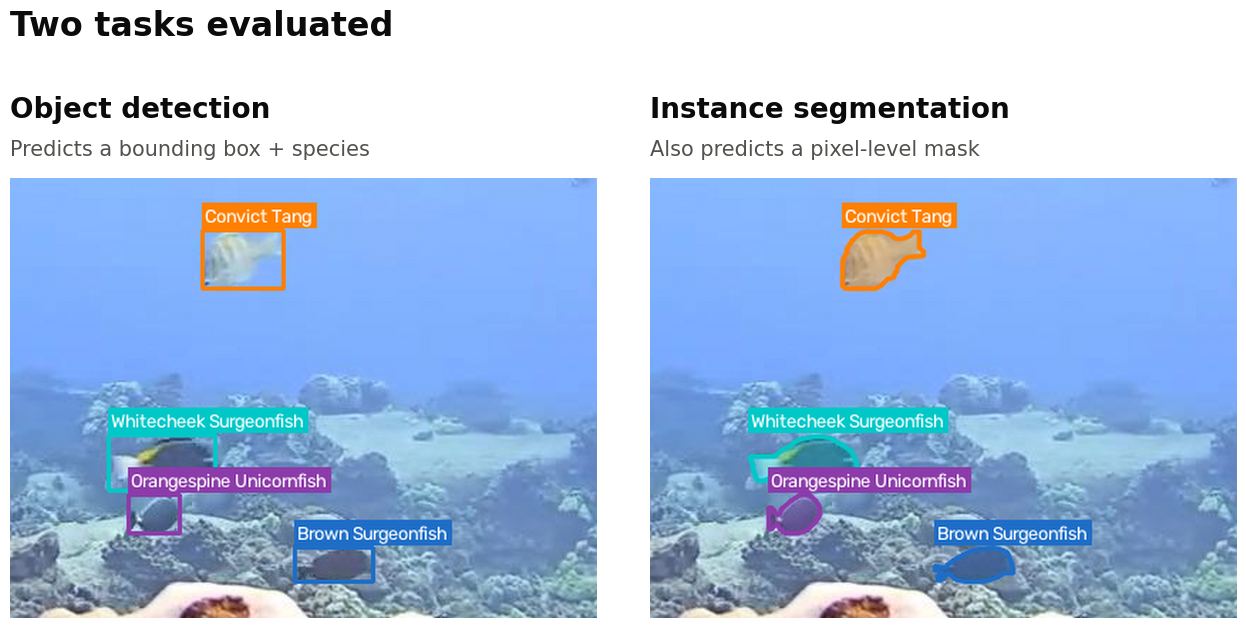

In [9]:
a = plt.imread(f'{REPORT}/box_vs_mask/a_boxes.png')[70:380, 480:893]
b = plt.imread(f'{REPORT}/box_vs_mask/b_masks.png')[70:380, 480:893]
fig = plt.figure(figsize=FS)
for i, (img, t, s) in enumerate([(a, 'Object detection', 'Predicts a bounding box + species'),
                                 (b, 'Instance segmentation', 'Also predicts a pixel-level mask')]):
    x = 0.04 + i * 0.48; hh = 0.44 * 13.33 / 7.5 * img.shape[0] / img.shape[1]
    ax = fig.add_axes([x, 0.74 - hh, 0.44, hh]); ax.imshow(img, interpolation='lanczos'); ax.axis('off')
    fig.text(x, 0.82, t, fontsize=20, fontweight='bold', color=T['ink'])
    fig.text(x, 0.77, s, fontsize=15, color=T['ink2'])
fig.text(0.04, 0.93, 'Two tasks evaluated', fontsize=24, fontweight='bold', color=T['ink'])
save(fig, '06_detection_vs_segmentation')

## 07 RQ1: finding fish vs identifying the species

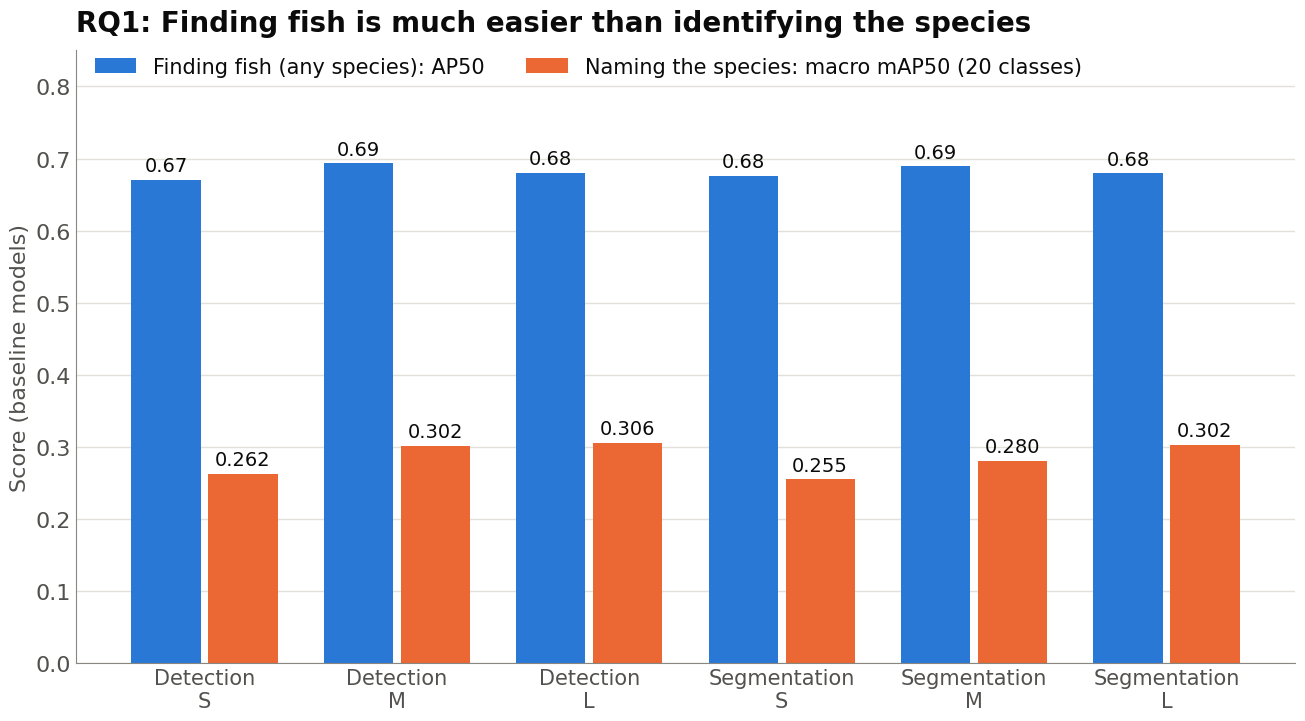

In [10]:
fig, ax = plt.subplots(figsize=FS)
x = np.arange(6); w = 0.36
af = [ANYFISH[s] for s in SETUPS]; mc = [MACRO[s] for s in SETUPS]
ax.bar(x - w / 2 - 0.02, af, w, color=T['blue'], label='Finding fish (any species): AP50')
ax.bar(x + w / 2 + 0.02, mc, w, color=T['orange'], label='Naming the species: macro mAP50 (20 classes)')
for i in range(6):
    ax.text(x[i] - w / 2 - 0.02, af[i] + 0.012, f'{af[i]:.2f}', ha='center', fontsize=14)
    ax.text(x[i] + w / 2 + 0.02, mc[i] + 0.012, f'{mc[i]:.3f}', ha='center', fontsize=14)
ax.set_xticks(x); ax.set_xticklabels([LAB[s].replace(' ', '\n', 1) for s in SETUPS], fontsize=15)
ax.set_ylim(0, 0.85); ax.set_ylabel('Score (baseline models)'); clean(ax)
ax.legend(loc='upper left', ncol=2, bbox_to_anchor=(0, 1.02))
ax.set_title('RQ1: Finding fish is much easier than identifying the species')
fig.tight_layout(); save(fig, '07_rq1_detection_vs_species')

## 08 RQ2: focus species, all six models

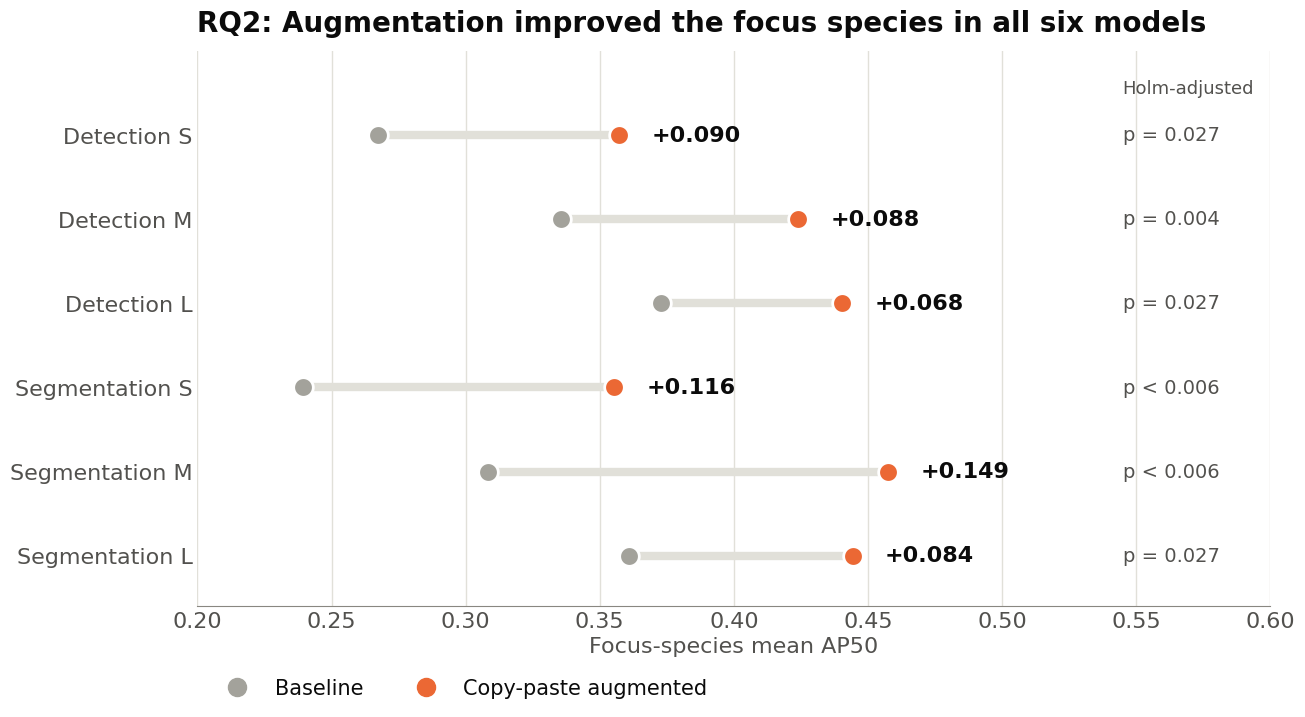

In [11]:
fig, ax = plt.subplots(figsize=FS)
order = SETUPS[::-1]
for i, s in enumerate(order):
    b, a = FOCUS_BASE[s], FOCUS_AUG[s]
    ax.plot([b, a], [i, i], color=T['grid'], lw=6, solid_capstyle='round', zorder=1)
    ax.scatter(b, i, s=200, color=T['base'], zorder=3, edgecolor=T['bg'], lw=2)
    ax.scatter(a, i, s=200, color=T['orange'], zorder=3, edgecolor=T['bg'], lw=2)
    ax.text(a + 0.012, i, f'+{a - b:.3f}', va='center', fontsize=16, fontweight='bold')
    ax.text(0.545, i, HOLM[s], va='center', fontsize=14, color=T['ink2'])
ax.set_yticks(range(6)); ax.set_yticklabels([LAB[s] for s in order], fontsize=16)
ax.set_xlim(0.2, 0.6); ax.set_ylim(-0.6, 6.0); ax.set_xlabel('Focus-species mean AP50'); clean(ax, grid='x')
ax.spines['left'].set_visible(False)
ax.text(0.545, 5.55, 'Holm-adjusted', fontsize=13, color=T['ink2'], va='center')
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=13, color=T['base']),
                   Line2D([], [], marker='o', ls='', ms=13, color=T['orange'])],
          labels=['Baseline', 'Copy-paste augmented'], loc='lower left', ncol=2, bbox_to_anchor=(0, -0.2))
ax.set_title('RQ2: Augmentation improved the focus species in all six models')
fig.tight_layout(); save(fig, '08_rq2_focus_species')

## 09 Per-species gains

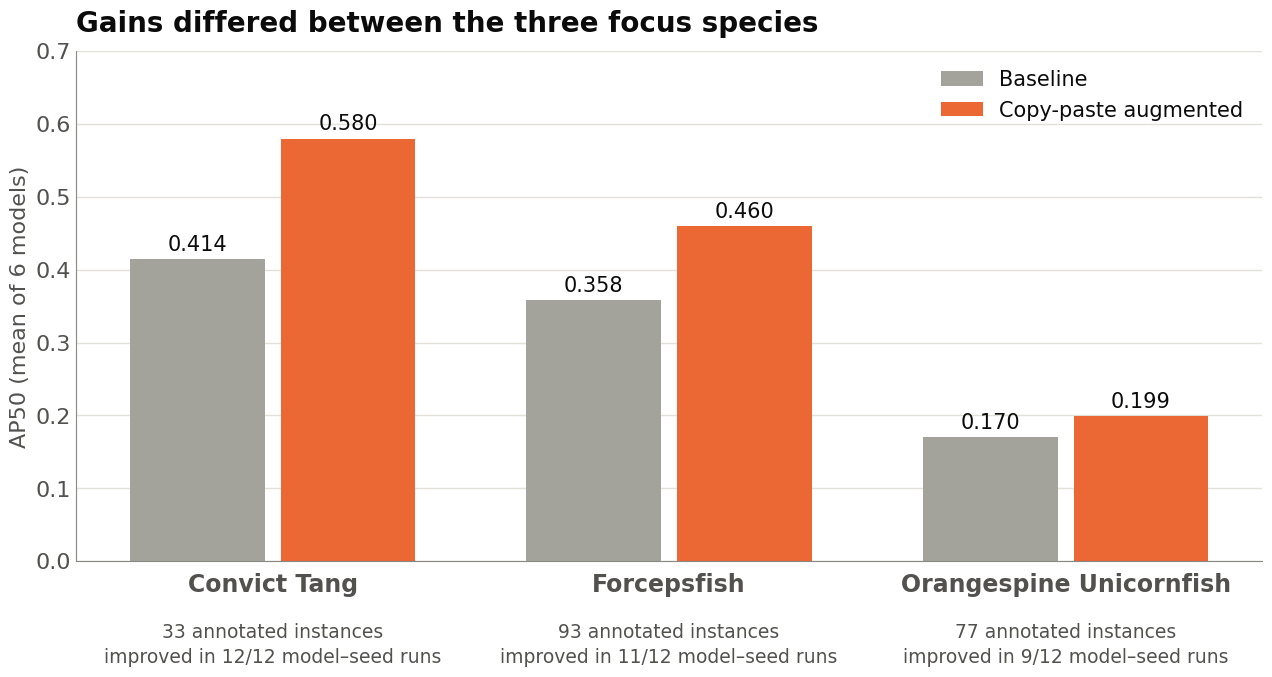

In [12]:
fig, ax = plt.subplots(figsize=FS)
sp = ['Convict Tang', 'Forcepsfish', 'Orangespine Unicornfish']; w = 0.34
for j, sname in enumerate(sp):
    b, a, wins = SPECIES_AVG[sname]
    ax.bar(j - w / 2 - 0.02, b, w, color=T['base'], label='Baseline' if j == 0 else None)
    ax.bar(j + w / 2 + 0.02, a, w, color=T['orange'], label='Copy-paste augmented' if j == 0 else None)
    ax.text(j - w / 2 - 0.02, b + 0.012, f'{b:.3f}', ha='center', fontsize=15)
    ax.text(j + w / 2 + 0.02, a + 0.012, f'{a:.3f}', ha='center', fontsize=15)
    ax.text(j, -0.085, f'{COUNTS[sname]} annotated instances\nimproved in {wins}/12 model–seed runs', ha='center',
            va='top', fontsize=13.5, color=T['ink2'], linespacing=1.4)
ax.set_xticks(range(3)); ax.set_xticklabels(sp, fontsize=17, fontweight='bold'); ax.tick_params(axis='x', pad=8)
ax.set_ylim(0, 0.7); ax.set_ylabel('AP50 (mean of 6 models)'); clean(ax); ax.legend(loc='upper right')
ax.set_title('Gains differed between the three focus species')
fig.subplots_adjust(left=0.08, right=0.97, top=0.88, bottom=0.2); save(fig, '09_species_gains')

## 10 Error breakdown

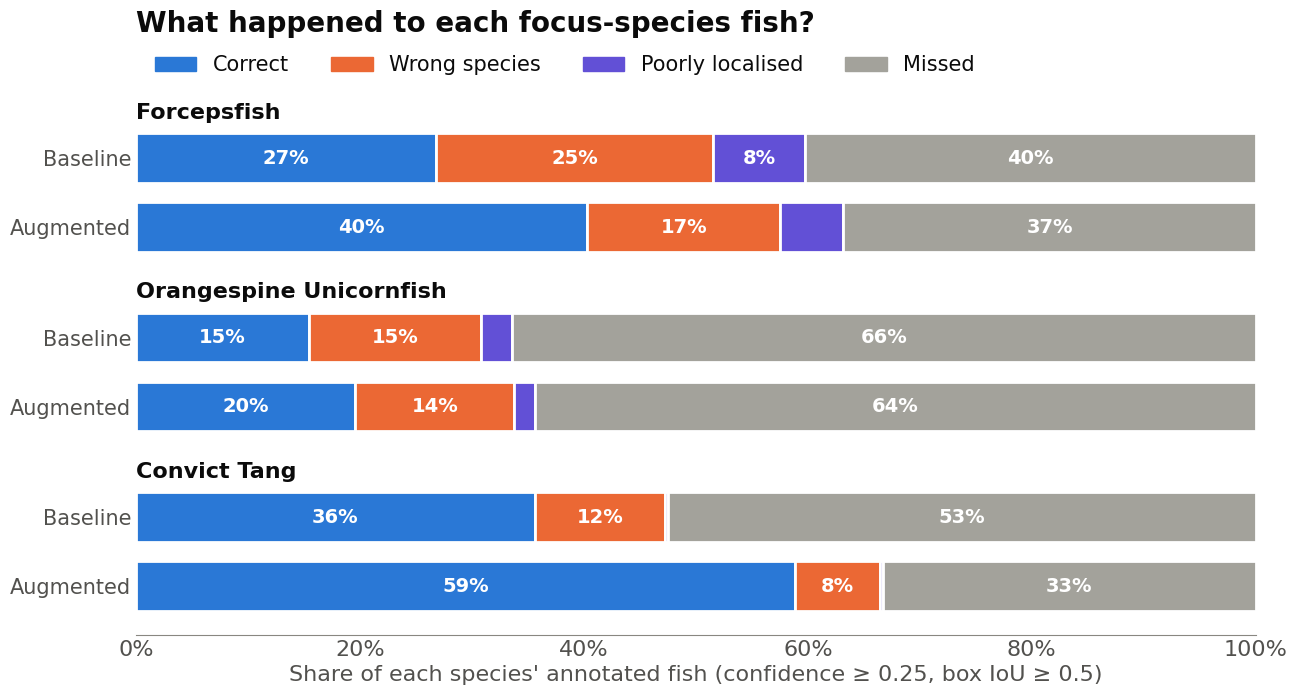

In [13]:
fig, ax = plt.subplots(figsize=FS)
sp = ['Forcepsfish', 'Orangespine Unicornfish', 'Convict Tang']
cats = ['Correct', 'Wrong species', 'Poorly localised', 'Missed']; cc = [T['blue'], T['orange'], T['violet'], T['base']]
yy, ys, ylab = 0, [], []
for sname in sp:
    for arm in ['Baseline', 'Augmented']:
        left = 0
        for v, col in zip(FATE[sname][arm], cc):
            ax.barh(yy, v, left=left, color=col, height=0.72, edgecolor=T['bg'], lw=2)
            if v >= 0.06:
                ax.text(left + v / 2, yy, f'{v:.0%}', ha='center', va='center', fontsize=14, fontweight='bold',
                        color='white' if col != T['base'] or THEME == 'light' else T['bg'])
            left += v
        ylab.append(arm); ys.append(yy); yy += 1
    yy += 0.6
ax.set_yticks(ys); ax.set_yticklabels(ylab, fontsize=15); ax.invert_yaxis()
for j, sname in enumerate(sp):
    ax.text(0, ys[2 * j] - 0.66, sname, ha='left', va='center', fontsize=16, fontweight='bold',
            transform=ax.get_yaxis_transform())
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Share of each species' annotated fish (confidence ≥ 0.25, box IoU ≥ 0.5)")
clean(ax, grid=None); ax.spines['left'].set_visible(False)
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=c) for c in cc], labels=cats, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.03))
ax.set_title('What happened to each focus-species fish?', pad=56)
fig.subplots_adjust(left=0.13, right=0.97, top=0.82, bottom=0.12); save(fig, '10_error_breakdown')

## 11 Non-target species and any-fish detection

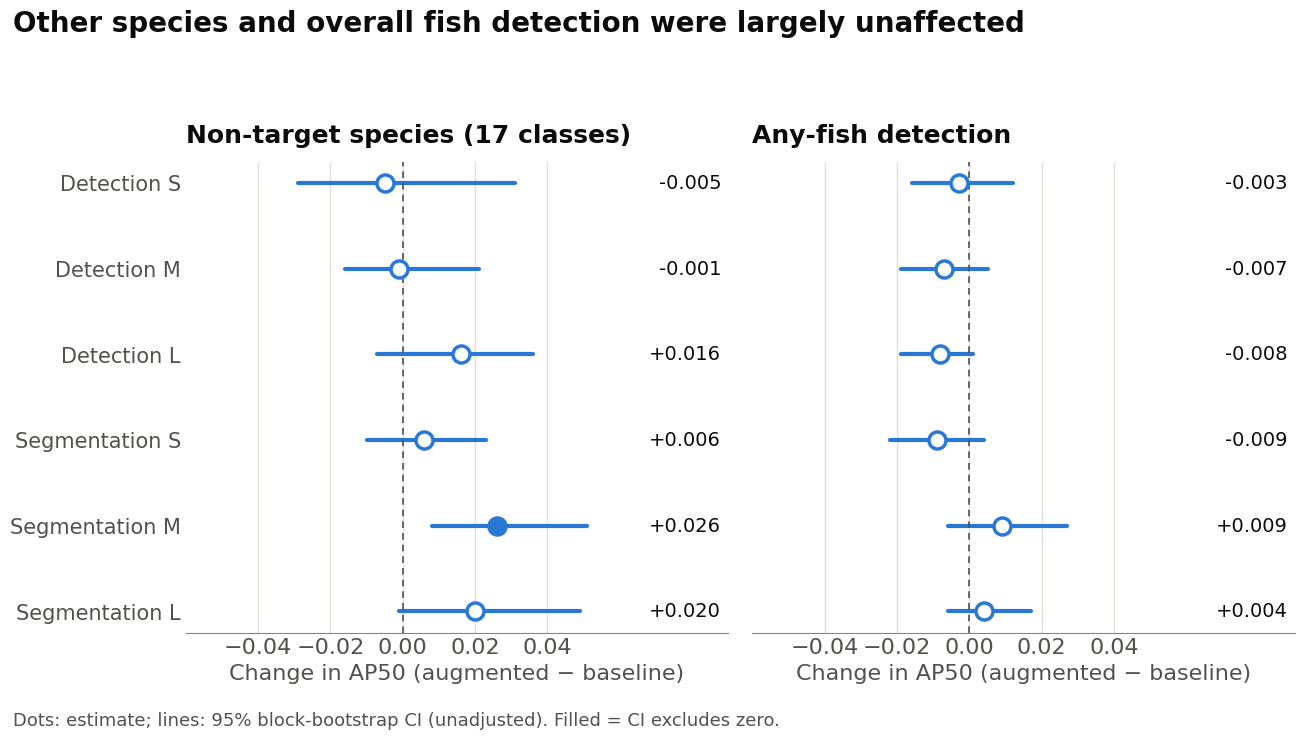

In [14]:
fig, axs = plt.subplots(1, 2, figsize=FS, sharey=True)
order = SETUPS[::-1]
for ax, data, title in [(axs[0], D_NONFOCUS, 'Non-target species (17 classes)'), (axs[1], D_ANYFISH, 'Any-fish detection')]:
    for i, s in enumerate(order):
        e, lo, hi = data[s]; sig = lo > 0 or hi < 0
        ax.plot([lo, hi], [i, i], color=T['blue'], lw=3, solid_capstyle='round')
        ax.scatter(e, i, s=150, color=T['blue'] if sig else T['bg'], edgecolor=T['blue'], lw=2.5, zorder=3)
        ax.text(0.088, i, f'{e:+.3f}', va='center', ha='right', fontsize=14)
    ax.axvline(0, color=T['ink2'], lw=1.2, ls=(0, (4, 3)))
    ax.set_xlim(-0.06, 0.09); ax.set_xticks([-0.04, -0.02, 0, 0.02, 0.04]); ax.set_title(title, fontsize=18); clean(ax, grid='x')
    ax.spines['left'].set_visible(False); ax.set_xlabel('Change in AP50 (augmented − baseline)')
axs[0].set_yticks(range(6)); axs[0].set_yticklabels([LAB[s] for s in order], fontsize=15)
fig.suptitle('Other species and overall fish detection were largely unaffected', x=0.02, ha='left',
             fontsize=20, fontweight='bold', color=T['ink'])
fig.text(0.02, 0.025, 'Dots: estimate; lines: 95% block-bootstrap CI (unadjusted). Filled = CI excludes zero.',
         fontsize=13, color=T['ink2'])
fig.tight_layout(rect=(0, 0.05, 1, 0.93)); save(fig, '11_non_target')

## 12 Augmentation vs a bigger model

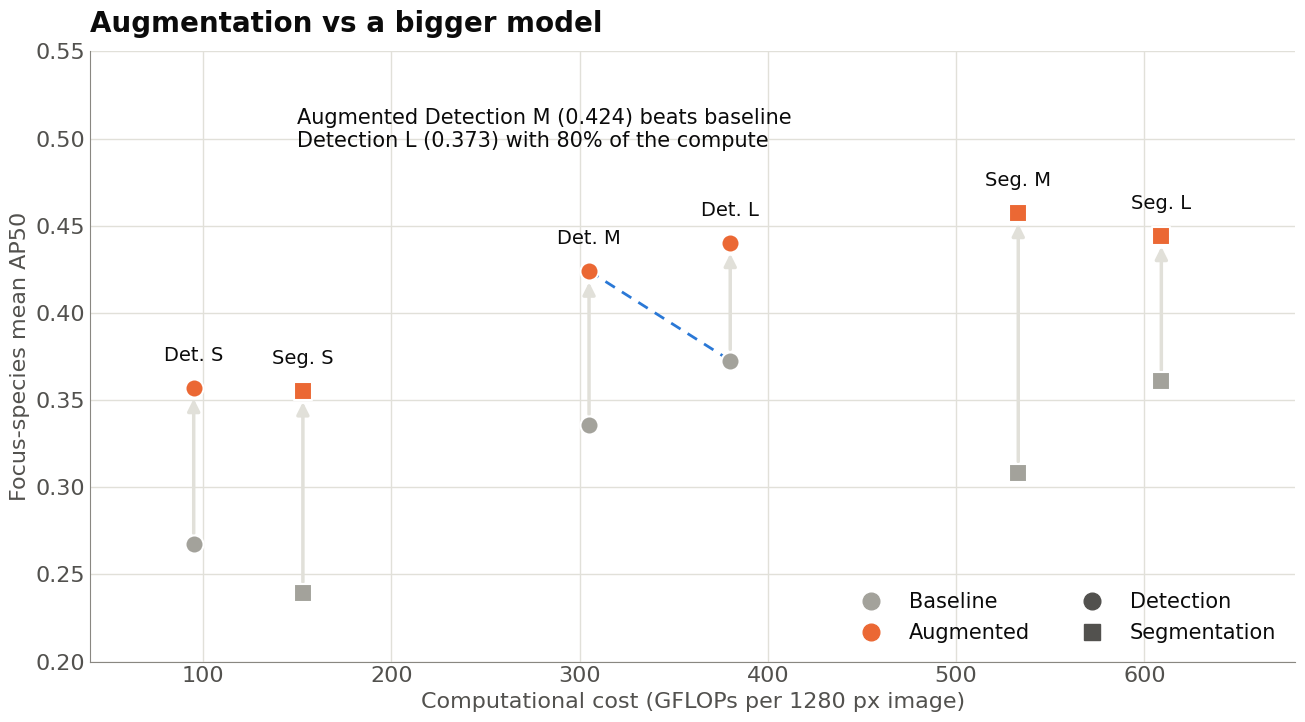

In [15]:
fig, ax = plt.subplots(figsize=FS)
for s in SETUPS:
    b, a, g = FOCUS_BASE[s], FOCUS_AUG[s], GFLOPS[s]; mk = 'o' if s.startswith('detect') else 's'
    ax.annotate('', (g, a), (g, b), arrowprops=dict(arrowstyle='-|>', color=T['grid'], lw=2.5, mutation_scale=18, shrinkA=8, shrinkB=8))
    ax.scatter(g, b, s=170, marker=mk, color=T['base'], zorder=3, edgecolor=T['bg'], lw=1.5)
    ax.scatter(g, a, s=170, marker=mk, color=T['orange'], zorder=3, edgecolor=T['bg'], lw=1.5)
    ax.text(g, a + 0.013, LAB[s].replace('Detection', 'Det.').replace('Segmentation', 'Seg.'), fontsize=14, ha='center', va='bottom')
am, bl = FOCUS_AUG['detect_m'], FOCUS_BASE['detect_l']
ax.plot([GFLOPS['detect_m'], GFLOPS['detect_l']], [am, bl], color=T['blue'], lw=2, ls=(0, (4, 3)))
ax.text(150, 0.505, f'Augmented Detection M ({am:.3f}) beats baseline\nDetection L ({bl:.3f}) with '
        f'{GFLOPS["detect_m"] / GFLOPS["detect_l"]:.0%} of the compute', fontsize=15, va='center')
ax.set_xlim(40, 680); ax.set_ylim(0.2, 0.55)
ax.set_xlabel('Computational cost (GFLOPs per 1280 px image)'); ax.set_ylabel('Focus-species mean AP50'); clean(ax, grid='both')
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=12, color=T['base']), Line2D([], [], marker='o', ls='', ms=12, color=T['orange']),
                   Line2D([], [], marker='o', ls='', ms=12, color=T['ink2']), Line2D([], [], marker='s', ls='', ms=12, color=T['ink2'])],
          labels=['Baseline', 'Augmented', 'Detection', 'Segmentation'], loc='lower right', ncol=2)
ax.set_title('Augmentation vs a bigger model')
fig.tight_layout(); save(fig, '12_efficiency')